## Model Training

#### 1.1 Import Data and Required Packages
##### Importing Pandas, Numpy, Matplotlib, Seaborn and Warings Library.

In [1]:
# Basic Import
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns
# Modelling
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor,AdaBoostRegressor
from sklearn.svm import SVR
from sklearn.linear_model import LinearRegression, Ridge,Lasso
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.model_selection import RandomizedSearchCV
from catboost import CatBoostRegressor
from xgboost import XGBRegressor
import warnings

#### Import the CSV Data as Pandas DataFrame

In [2]:
df = pd.read_csv("./Data/after_preprocess.csv")

#### Show Top 5 Records

In [3]:
df.head()

,NAME,DIV,DEP,LOC,LEAVE DATE,TYPE,NO DAYS,LEAVE MONTH,LEAVE YEAR,LEAVE DAY OF WEEK,PREV LEAVE DATE,DAYS SINCE LAST LEAVE,NEXT LEAVE DATE,DAYS UNTIL NEXT LEAVE,CUMULATIVE LEAVE COUNT
0,A.A.A.R.DE SILVA,DHA,SAB,SEU,2020-01-31,CS,1.0,1,2020,4,2020-01-11,20.0,2020-02-01,1.0,2
1,A.A.A.R.DE SILVA,DHA,SAB,SEU,2020-02-01,CS,0.5,2,2020,5,2020-01-31,1.0,2020-02-15,14.0,3
2,A.A.A.R.DE SILVA,DHA,SAB,SEU,2020-02-15,AL,0.5,2,2020,5,2020-02-01,14.0,2020-02-18,3.0,4
3,A.A.A.R.DE SILVA,DHA,SAB,SEU,2020-02-18,CS,1.0,2,2020,1,2020-02-15,3.0,2020-03-10,21.0,5
4,A.A.A.R.DE SILVA,DHA,SAB,SEU,2020-03-10,CS,1.0,3,2020,1,2020-02-18,21.0,2020-06-11,93.0,6


In [4]:
df = df.drop(columns=['LEAVE DATE', 'PREV LEAVE DATE', 'NEXT LEAVE DATE'])
df

,NAME,DIV,DEP,LOC,TYPE,NO DAYS,LEAVE MONTH,LEAVE YEAR,LEAVE DAY OF WEEK,DAYS SINCE LAST LEAVE,DAYS UNTIL NEXT LEAVE,CUMULATIVE LEAVE COUNT
0,A.A.A.R.DE SILVA,DHA,SAB,SEU,CS,1.0,1,2020,4,20.0,1.0,2
1,A.A.A.R.DE SILVA,DHA,SAB,SEU,CS,0.5,2,2020,5,1.0,14.0,3
2,A.A.A.R.DE SILVA,DHA,SAB,SEU,AL,0.5,2,2020,5,14.0,3.0,4
3,A.A.A.R.DE SILVA,DHA,SAB,SEU,CS,1.0,2,2020,1,3.0,21.0,5
4,A.A.A.R.DE SILVA,DHA,SAB,SEU,CS,1.0,3,2020,1,21.0,93.0,6
...,...,...,...,...,...,...,...,...,...,...,...,...
239834,Y.S.D.DHARMATHILAKA,DMD,SRC,FIU,SK,1.0,10,2024,1,1.0,37.0,7
239835,Y.S.D.DHARMATHILAKA,DMD,SRC,FIU,DL,1.0,11,2024,3,37.0,63.0,8
239836,Y.S.D.DHARMATHILAKA,DMD,SRC,FIU,SK,1.0,1,2025,3,63.0,4.0,1
239837,Y.S.D.DHARMATHILAKA,DMD,SRC,FIU,SK,1.0,1,2025,0,4.0,10.0,2


#### Preparing X and Y variables

In [5]:
X = df.drop(columns=['DAYS UNTIL NEXT LEAVE'],axis=1)

In [6]:
X.head()

,NAME,DIV,DEP,LOC,TYPE,NO DAYS,LEAVE MONTH,LEAVE YEAR,LEAVE DAY OF WEEK,DAYS SINCE LAST LEAVE,CUMULATIVE LEAVE COUNT
0,A.A.A.R.DE SILVA,DHA,SAB,SEU,CS,1.0,1,2020,4,20.0,2
1,A.A.A.R.DE SILVA,DHA,SAB,SEU,CS,0.5,2,2020,5,1.0,3
2,A.A.A.R.DE SILVA,DHA,SAB,SEU,AL,0.5,2,2020,5,14.0,4
3,A.A.A.R.DE SILVA,DHA,SAB,SEU,CS,1.0,2,2020,1,3.0,5
4,A.A.A.R.DE SILVA,DHA,SAB,SEU,CS,1.0,3,2020,1,21.0,6


In [7]:
y = df['DAYS UNTIL NEXT LEAVE']
y

0          1.0
1         14.0
2          3.0
3         21.0
4         93.0
          ... 
239834    37.0
239835    63.0
239836     4.0
239837    10.0
239838     6.0
Name: DAYS UNTIL NEXT LEAVE, Length: 239839, dtype: float64

#### Identifying categorical and numerical features

In [8]:
# define numerical & categorical columns
numeric_features = [feature for feature in df.columns if df[feature].dtype != 'O']
categorical_features = [feature for feature in df.columns if df[feature].dtype == 'O']

# print columns
print('We have {} numerical features : {}'.format(len(numeric_features), numeric_features))
print('\nWe have {} categorical features : {}'.format(len(categorical_features), categorical_features))

We have 7 numerical features : ['NO DAYS', 'LEAVE MONTH', 'LEAVE YEAR', 'LEAVE DAY OF WEEK', 'DAYS SINCE LAST LEAVE', 'DAYS UNTIL NEXT LEAVE', 'CUMULATIVE LEAVE COUNT']

We have 5 categorical features : ['NAME', 'DIV', 'DEP', 'LOC', 'TYPE']


In [9]:
print("Categories in 'NAME' variable:     ",end=" " )
print(df['NAME'].unique())

print("Categories in 'DIV' variable:  ",end=" ")
print(df['DIV'].unique())

print("Categories in 'DEP' variable:",end=" " )
print(df['DEP'].unique())

print("Categories in 'LOC' variable:     ",end=" " )
print(df['LOC'].unique())

print("Categories in 'TYPE' variable:     ",end=" " )
print(df['TYPE'].unique())

Categories in 'NAME' variable:      ['A.A.A.R.DE SILVA' 'A.A.C.P.AMARASINGHE' 'A.A.D.A.R.AMARASINGHE' ...
 'Y.P.L.R.K. DISSANAYAKE' 'Y.R.A.P.M. RAJAPAKSE' 'Y.S.D.DHARMATHILAKA']
Categories in 'DIV' variable:   ['DHA' 'DPR' 'DYA' 'DBU' 'DMD' 'DMP' 'DFI' 'DPH' 'DPJ' 'DRD' 'DCH' 'DQA'
 'DPE']
Categories in 'DEP' variable: ['SAB' 'SSO' 'SHC' 'SDE' 'SMT' 'SDM' 'SHE' 'SRC' 'SHD' 'SHT' 'SWE' 'SDS'
 'SMO' 'SEA' 'SQC' 'SSC' 'SMG' 'SMP' 'SAC' 'SIR' 'SEM' 'SIT' 'SSR' 'SSM'
 'SYD' 'SMA' 'SLE' 'SFI' 'SIN' 'SPJ' 'SPR' 'SAA' 'SBU' 'SCH' 'SHA' 'SMN'
 'SES' 'SNE' 'SQA' 'SMD' 'SRE']
Categories in 'LOC' variable:      ['SEU' 'COM' 'SWC' 'FIS' 'PPH' 'FIE' 'DOS' 'GAC' 'DFS' 'TRC' 'WTS' 'FIU'
 'PP4' 'SWR' 'MAT' 'BLP' 'KIT' 'DEO' 'MAO' 'MEW' 'SEE' 'ELW' 'ENW' 'MEC'
 'AUW' 'PFS' 'ALW' 'QCO' 'ADU' 'PPM' 'TRA' 'CAL' 'SEC' 'MPO' 'NTS' 'PEO'
 'PAY' 'BLU' 'PE1' 'SCA' 'EST' 'DMO' 'WHA' 'ITO' 'STD' 'SVG' 'WEP' 'STC'
 'FTS' 'MAS' 'KBL' 'WEL' 'SRP' 'YDU' 'SHB' 'WSO' 'LOP' 'MAR' 'PFH' 'PE2'
 'CAR' 'IMP' 'SAF' 'SHR' 'LE

#### Created column transformer pipeline

In [10]:
from sklearn.impute import SimpleImputer

# Create Column Transformer with 3 types of transformers
numerical_columns = ['NO DAYS', 'LEAVE MONTH', 'LEAVE YEAR', 'LEAVE DAY OF WEEK', 'DAYS SINCE LAST LEAVE', 'CUMULATIVE LEAVE COUNT']
categorical_columns = ['NAME', 'DIV', 'DEP', 'LOC', 'TYPE']

from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

num_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")), #handling missing values
        ("scaler", StandardScaler(with_mean=False))
    ]
)

cat_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("one_hot_encoder", OneHotEncoder(handle_unknown='ignore')),
        ("scaler", StandardScaler(with_mean=False))
    ]
)

preprocessor = ColumnTransformer([
    ("num_pipeline", num_pipeline, numerical_columns),
    ("cat_pipeline", cat_pipeline, categorical_columns)
])

In [11]:
X = preprocessor.fit_transform(X)

In [12]:
X.shape

(239839, 1702)

#### Splitting data to test and train

In [13]:
# separate dataset into train and test
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42)
X_train.shape, X_test.shape

((191871, 1702), (47968, 1702))

#### Create an Evaluate Function to give all metrics after model Training

In [14]:
def evaluate_model(true, predicted):
    mae = mean_absolute_error(true, predicted)
    mse = mean_squared_error(true, predicted)
    rmse = np.sqrt(mean_squared_error(true, predicted))
    r2_square = r2_score(true, predicted)
    return mae, rmse, r2_square

#### Hyperparameter Tuning 

In [25]:
from sklearn.model_selection import GridSearchCV

# Define models and parameters
models = {
    "Linear Regression": LinearRegression(),
    "Lasso": Lasso(),
    "Ridge": Ridge(),
    "K-Neighbors Regressor": KNeighborsRegressor(),
    "Decision Tree": DecisionTreeRegressor(),
    "Random Forest Regressor": RandomForestRegressor(),
    "XGBRegressor": XGBRegressor(),
    "CatBoosting Regressor": CatBoostRegressor(verbose=False),
    "AdaBoost Regressor": AdaBoostRegressor()
}

params = {
    "Decision Tree": {
        'criterion': ['squared_error', 'friedman_mse', 'absolute_error']
    },
    "Random Forest": {
        'n_estimators': [8, 16, 32, 64, 128, 256]
    },
    "Gradient Boosting": {
        'learning_rate': [0.1, 0.01, 0.05, 0.001],
        'subsample': [0.6, 0.7, 0.75, 0.8, 0.85, 0.9],
        'n_estimators': [8, 16, 32, 64, 128, 256]
    },
    "Linear Regression": {},
    "XGBRegressor": {
        'learning_rate': [0.1, 0.01, 0.05, 0.001],
        'n_estimators': [8, 16, 32, 64, 128, 256]
    },
    "CatBoosting Regressor": {
        'depth': [6, 8],
        'learning_rate': [0.01, 0.05, 0.1, 0.6],
        'iterations': [30, 50, 100]
    },
    "AdaBoost Regressor": {
        'learning_rate': [0.1, 0.01, 0.5, 0.001],
        'n_estimators': [8, 16, 32, 64, 128, 256]
    }
}

model_list = []
best_params_list = []
r2_list = []

# Loop through each model
for model_name, model in models.items():
    print(f"Processing {model_name}...")
    param = params.get(model_name, {})  # Get params for the current model

    # Perform GridSearchCV if parameters are available
    if param:
        grid_search = GridSearchCV(estimator=model, param_grid=param, cv=3, scoring='r2', verbose=1, error_score=np.nan)
        grid_search.fit(X_train, y_train)
        best_model = grid_search.best_estimator_
        best_params = grid_search.best_params_
    else:
        # Fit without GridSearchCV if no parameters are defined
        best_model = model
        best_model.fit(X_train, y_train)
        best_params = "Default parameters"

    # Evaluate the best model
    y_train_pred = best_model.predict(X_train)
    y_test_pred = best_model.predict(X_test)
    
    model_train_mae, model_train_rmse, model_train_r2 = evaluate_model(y_train, y_train_pred)
    model_test_mae, model_test_rmse, model_test_r2 = evaluate_model(y_test, y_test_pred)
    
    # Append results
    model_list.append(model_name)
    best_params_list.append(best_params)
    r2_list.append(model_test_r2)
    
    # Print results
    print(f"{model_name} - Best Parameters: {best_params}")
    print('Model performance for Test set')
    print("- Root Mean Squared Error: {:.4f}".format(model_test_rmse))
    print("- Mean Absolute Error: {:.4f}".format(model_test_mae))
    print("- R2 Score: {:.4f}".format(model_test_r2))
    print("=" * 50)

Processing Linear Regression...
Linear Regression - Best Parameters: Default parameters
Model performance for Test set
- Root Mean Squared Error: 13.3902
- Mean Absolute Error: 7.8783
- R2 Score: 0.0725
Processing Lasso...
Lasso - Best Parameters: Default parameters
Model performance for Test set
- Root Mean Squared Error: 13.7530
- Mean Absolute Error: 8.1985
- R2 Score: 0.0216
Processing Ridge...
Ridge - Best Parameters: Default parameters
Model performance for Test set
- Root Mean Squared Error: 13.3902
- Mean Absolute Error: 7.8783
- R2 Score: 0.0725
Processing K-Neighbors Regressor...


KeyboardInterrupt: 

#### Single model training

In [16]:
lin_model = XGBRegressor(n_estimators=230, learning_rate=0.091, max_depth=18, random_state=42)
lin_model = lin_model.fit(X_train, y_train)
y_pred = lin_model.predict(X_test)
model_test_mae, model_test_rmse, model_test_r2 = evaluate_model(y_test, y_pred)
# score = r2_score(y_test, y_pred)*100 
print(" r2 score of the model is %.2f" %model_test_r2)
print(" mae score of the model is %.2f" %model_test_mae)

 r2 score of the model is 0.11
 mae score of the model is 7.53


#### Custom date accuracy function

In [38]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Define a custom accuracy function
def custom_date_accuracy(y_true, y_pred, tolerance=14):
    """
    Calculate the percentage of predictions within the given tolerance range.
    Args:
        y_true (array-like): True target values.
        y_pred (array-like): Predicted target values.
        tolerance (int): Number of days for the acceptable range (default is ±14 days).
    Returns:
        float: Accuracy as a percentage.
    """
    # Ensure inputs are numpy arrays
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)

    # Calculate the absolute difference in days
    differences = np.abs(y_pred - y_true)

    # Check how many predictions fall within the tolerance range
    within_tolerance = np.sum(differences <= tolerance)

    # Calculate accuracy as a percentage
    accuracy = (within_tolerance / len(y_true)) * 100
    return accuracy

# def next_7_days_accuracy(y_true, y_pred):
#     """
#     Calculate the percentage of predictions that are within the next 7 days.
#     Args:
#         y_true (array-like): True target values.
#         y_pred (array-like): Predicted target values.
#     Returns:
#         float: Accuracy as a percentage.
#     """
#     # Ensure inputs are numpy arrays
#     y_true = np.array(y_true)
#     y_pred = np.array(y_pred)
#     
#     # Calculate the difference
#     differences = y_pred - y_true
#     
#     # Check predictions strictly within the next 7 days (greater but not more than 7)
#     within_next_7_days = np.sum((differences > 0) & (differences <= 7))
#     
#     # Calculate accuracy as a percentage
#     accuracy = (within_next_7_days / len(y_true)) * 100
#     return accuracy

# Evaluate the CatBoost model with the custom accuracy metric
rf_model = RandomForestRegressor(n_estimators=20, random_state=42)
rf_model.fit(X_train, y_train)
y_pred = rf_model.predict(X_test)

# Custom accuracy 
tolerance_in_days = 7  # Define the tolerance range (±14 days)
date_accuracy = custom_date_accuracy(y_test, y_pred, tolerance=tolerance_in_days)
#date_accuracy = next_7_days_accuracy(y_test, y_pred)

# Print the results
print(f"Custom Date Accuracy: {date_accuracy:.2f}%")

Custom Date Accuracy: 68.60%


In [74]:
df.columns

Index(['NAME', 'DIV', 'DEP', 'LOC', 'TYPE', 'NO DAYS', 'LEAVE MONTH',
       'LEAVE YEAR', 'LEAVE DAY OF WEEK', 'DAYS SINCE LAST LEAVE',
       'DAYS UNTIL NEXT LEAVE', 'CUMULATIVE LEAVE COUNT'],
      dtype='object')

                                   Feature  Importance
1                num_pipeline__LEAVE MONTH    0.110141
5     num_pipeline__CUMULATIVE LEAVE COUNT    0.100924
4      num_pipeline__DAYS SINCE LAST LEAVE    0.074592
3          num_pipeline__LEAVE DAY OF WEEK    0.048668
2                 num_pipeline__LEAVE YEAR    0.040463
0                    num_pipeline__NO DAYS    0.012585
1673                 cat_pipeline__TYPE_AL    0.011031
1675                 cat_pipeline__TYPE_CS    0.010412
1684                 cat_pipeline__TYPE_SK    0.005765
236    cat_pipeline__NAME_D.L.WANIGASEKARA    0.004444


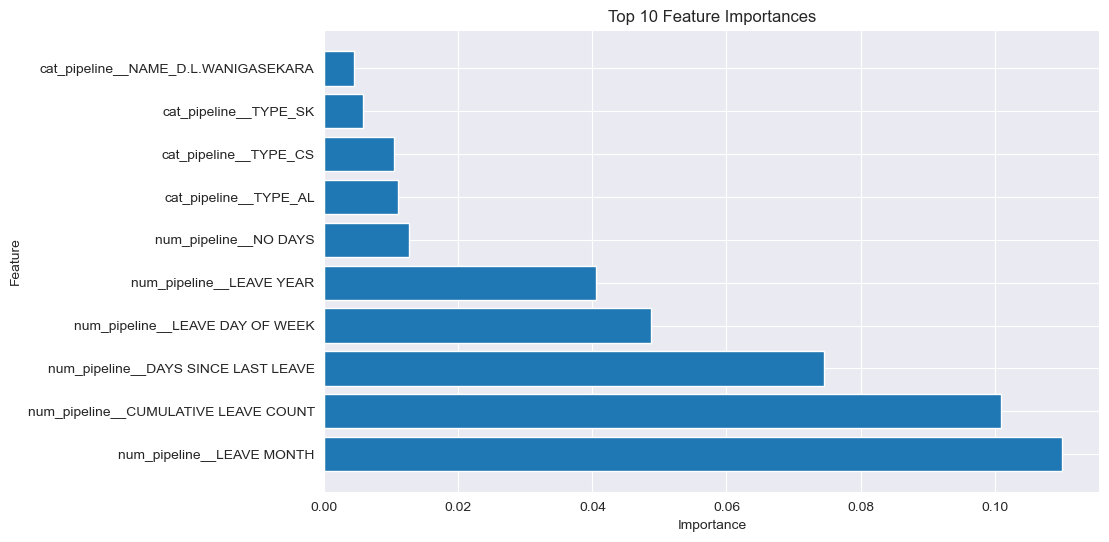

In [77]:
import pandas as pd
import matplotlib.pyplot as plt

# Assuming you used a ColumnTransformer or Pipeline for preprocessing
# Example: If you used a ColumnTransformer named `preprocessor`
feature_names = preprocessor.get_feature_names_out()

# Get feature importances from the trained model
feature_importances = rf_model.feature_importances_

# Create a DataFrame to display feature importances
importance_df = pd.DataFrame({
    'Feature': feature_names,  # Use feature names from the preprocessor
    'Importance': feature_importances
})

# Sort by importance
importance_df = importance_df.sort_values(by='Importance', ascending=False)

# Display the top 10 most important features
print(importance_df.head(10))

# Visualize feature importances
plt.figure(figsize=(10, 6))
plt.barh(importance_df['Feature'][:10], importance_df['Importance'][:10])
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.title('Top 10 Feature Importances')
plt.show()

#### Plotting predictions vs true values

In [91]:
from sklearn.tree import export_text
import pandas as pd

# If X_train is a sparse matrix, convert it to a dense DataFrame
X_train_dense = pd.DataFrame(X_train.toarray(), columns=feature_names)

# Extract a single decision tree from the forest
single_tree = rf_model.estimators_[0]  # Take the first tree

# Get decision rules
decision_path = export_text(single_tree, feature_names=X_train_dense.columns)

# Print decision logic
print(decision_path)

|--- num_pipeline__CUMULATIVE LEAVE COUNT <= 0.72
|   |--- cat_pipeline__LOC_WOQ <= 56.86
|   |   |--- num_pipeline__LEAVE YEAR <= 1509.43
|   |   |   |--- num_pipeline__LEAVE MONTH <= 1.29
|   |   |   |   |--- num_pipeline__LEAVE MONTH <= 0.72
|   |   |   |   |   |--- num_pipeline__DAYS SINCE LAST LEAVE <= 1.21
|   |   |   |   |   |   |--- cat_pipeline__NAME_H.K.D.KUMARA <= 21.58
|   |   |   |   |   |   |   |--- cat_pipeline__NAME_D.M.SOMARATHNA <= 21.58
|   |   |   |   |   |   |   |   |--- cat_pipeline__NAME_M.S.A.E.FERNANDO <= 22.80
|   |   |   |   |   |   |   |   |   |--- cat_pipeline__NAME_N.P.H.T.DISSANAYAKE <= 21.85
|   |   |   |   |   |   |   |   |   |   |--- cat_pipeline__NAME_M.L.A.SUMANAPALA <= 24.25
|   |   |   |   |   |   |   |   |   |   |   |--- truncated branch of depth 204
|   |   |   |   |   |   |   |   |   |   |--- cat_pipeline__NAME_M.L.A.SUMANAPALA >  24.25
|   |   |   |   |   |   |   |   |   |   |   |--- value: [165.00]
|   |   |   |   |   |   |   |   |   |--- cat_

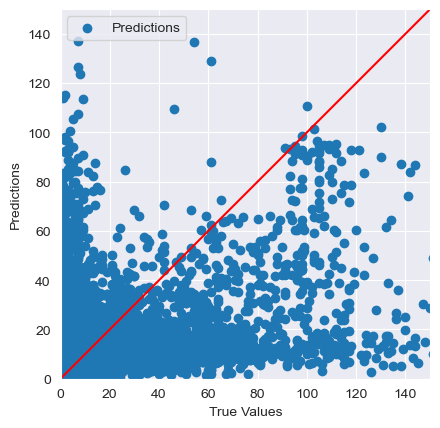

In [18]:
ax = plt.axes(aspect="equal")
plt.scatter(y_test, y_pred, label="Predictions")
plt.xlabel("True Values")
plt.ylabel("Predictions")
lims = [0,150]
plt.xlim(lims)
plt.ylim(lims)
plt.legend()
_ = plt.plot(lims, lims, c="red")

In [17]:
import os 
import sys
import numpy as np
import pandas as pd
import pickle
#from src.exception import CustomException
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import r2_score

#### Function to save objects 

In [40]:
def save_object(file_path, obj):
    dir_path = os.path.dirname(file_path)

    os.makedirs(dir_path, exist_ok=True)

    with open(file_path, "wb") as file_obj:
        pickle.dump(obj, file_obj)


#### Saving the pre-processor

In [23]:
save_object(
    file_path="./savedObj/preprocessor.pkl",
    obj=preprocessor
)

#### Saving the model

In [41]:
save_object(
    file_path="./savedObj/rf_model.pkl",
    obj=rf_model
)

#### Function to load objects

In [15]:
def load_object(file_path):
    with open(file_path, "rb") as file_obj:
        return pickle.load(file_obj)

#### Loading the saved files

In [18]:
preprocessor_path = './savedObj/preprocessor.pkl'
model_path = './savedObj/rf_model.pkl'
model = load_object(file_path=model_path)
preprocessor = load_object(file_path=preprocessor_path)

#### Reading the dataset with no next leave date

In [19]:
no_next_leave_date = pd.read_csv('./Data/data_without_next_leave.csv')
no_next_leave_date

,NAME,DIV,DEP,LOC,LEAVE DATE,TYPE,NO DAYS,LEAVE MONTH,LEAVE YEAR,LEAVE DAY OF WEEK,PREV LEAVE DATE,DAYS SINCE LAST LEAVE,NEXT LEAVE DATE,DAYS UNTIL NEXT LEAVE,CUMULATIVE LEAVE COUNT
0,A.A.A.R.DE SILVA,DHA,SAB,SEU,2025-01-06,CS,1.0,1,2025,0,2024-12-31,6.0,NaN,NaN,1
1,A.A.C.P.AMARASINGHE,DPR,SSO,COM,2025-02-21,AL,0.5,2,2025,4,2025-02-17,4.0,NaN,NaN,5
2,A.A.D.A.R.AMARASINGHE,DPR,SHC,SWC,2025-02-21,SK,1.0,2,2025,4,2025-02-20,1.0,NaN,NaN,16
3,A.A.D.C.B.AMARASINGHE,DPR,SDE,FIS,2025-01-27,SK,1.0,1,2025,0,2025-01-25,2.0,NaN,NaN,3
4,A.A.D.JEEWANTHA,DYA,SMT,PPH,2025-01-27,CS,1.0,1,2025,0,2025-01-24,3.0,NaN,NaN,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1543,Y.M.S. DILSHAN,DPR,SSO,ALW,2025-02-15,AL,0.5,2,2025,5,2025-02-03,12.0,NaN,NaN,4
1544,Y.P.L.M.DHARMARATNA,DPR,SDE,DFS,2025-02-14,CS,1.0,2,2025,4,2025-02-13,1.0,NaN,NaN,4
1545,Y.P.L.R.K. DISSANAYAKE,DHA,SWE,TRA,2024-11-30,AL,0.5,11,2024,5,2024-11-14,16.0,NaN,NaN,11
1546,Y.R.A.P.M. RAJAPAKSE,DBU,SSM,AFR,2025-02-13,AL,1.0,2,2025,3,2025-02-11,2.0,NaN,NaN,5


#### Dropping the unnecessary columns of the dataset

In [20]:
df = no_next_leave_date.drop(columns=['LEAVE DATE', 'PREV LEAVE DATE', 'NEXT LEAVE DATE', 'DAYS UNTIL NEXT LEAVE'])
df

,NAME,DIV,DEP,LOC,TYPE,NO DAYS,LEAVE MONTH,LEAVE YEAR,LEAVE DAY OF WEEK,DAYS SINCE LAST LEAVE,CUMULATIVE LEAVE COUNT
0,A.A.A.R.DE SILVA,DHA,SAB,SEU,CS,1.0,1,2025,0,6.0,1
1,A.A.C.P.AMARASINGHE,DPR,SSO,COM,AL,0.5,2,2025,4,4.0,5
2,A.A.D.A.R.AMARASINGHE,DPR,SHC,SWC,SK,1.0,2,2025,4,1.0,16
3,A.A.D.C.B.AMARASINGHE,DPR,SDE,FIS,SK,1.0,1,2025,0,2.0,3
4,A.A.D.JEEWANTHA,DYA,SMT,PPH,CS,1.0,1,2025,0,3.0,4
...,...,...,...,...,...,...,...,...,...,...,...
1543,Y.M.S. DILSHAN,DPR,SSO,ALW,AL,0.5,2,2025,5,12.0,4
1544,Y.P.L.M.DHARMARATNA,DPR,SDE,DFS,CS,1.0,2,2025,4,1.0,4
1545,Y.P.L.R.K. DISSANAYAKE,DHA,SWE,TRA,AL,0.5,11,2024,5,16.0,11
1546,Y.R.A.P.M. RAJAPAKSE,DBU,SSM,AFR,AL,1.0,2,2025,3,2.0,5


#### Scaling the data using the preprocessor

In [21]:
data_scaled = preprocessor.transform(df)
data_scaled

<1548x1689 sparse matrix of type '<class 'numpy.float64'>'
	with 16750 stored elements in Compressed Sparse Row format>

#### predicting the 'DAYS UNTIL NEXT LEAVE'

In [22]:
preds = model.predict(data_scaled)
preds

array([10.95,  5.95,  1.4 , ..., 10.25,  7.9 ,  7.65])

#### saving the predictions as a new column

In [23]:
no_next_leave_date['DAYS UNTIL NEXT LEAVE'] = preds
no_next_leave_date.head(5)

,NAME,DIV,DEP,LOC,LEAVE DATE,TYPE,NO DAYS,LEAVE MONTH,LEAVE YEAR,LEAVE DAY OF WEEK,PREV LEAVE DATE,DAYS SINCE LAST LEAVE,NEXT LEAVE DATE,DAYS UNTIL NEXT LEAVE,CUMULATIVE LEAVE COUNT
0,A.A.A.R.DE SILVA,DHA,SAB,SEU,2025-01-06,CS,1.0,1,2025,0,2024-12-31,6.0,NaN,10.95,1
1,A.A.C.P.AMARASINGHE,DPR,SSO,COM,2025-02-21,AL,0.5,2,2025,4,2025-02-17,4.0,NaN,5.95,5
2,A.A.D.A.R.AMARASINGHE,DPR,SHC,SWC,2025-02-21,SK,1.0,2,2025,4,2025-02-20,1.0,NaN,1.40,16
3,A.A.D.C.B.AMARASINGHE,DPR,SDE,FIS,2025-01-27,SK,1.0,1,2025,0,2025-01-25,2.0,NaN,1.95,3
4,A.A.D.JEEWANTHA,DYA,SMT,PPH,2025-01-27,CS,1.0,1,2025,0,2025-01-24,3.0,NaN,7.25,4


#### Converted the 'DAYS UNTIL NEXT LEAVE' column to a int type because it contains decimals values 

In [24]:
no_next_leave_date['DAYS UNTIL NEXT LEAVE'] = no_next_leave_date['DAYS UNTIL NEXT LEAVE'].astype(int)
no_next_leave_date['DAYS UNTIL NEXT LEAVE'].head()

0    10
1     5
2     1
3     1
4     7
Name: DAYS UNTIL NEXT LEAVE, dtype: int32

#### Creating the 'NEXT LEAVE DATE' column by adding the 'DAYS UNTIL NEXT LEAVE' to the 'LEAVE DATE'

In [25]:
no_next_leave_date['LEAVE DATE'] = pd.to_datetime(no_next_leave_date['LEAVE DATE'])
no_next_leave_date['NEXT LEAVE DATE'] = no_next_leave_date['LEAVE DATE'] + pd.to_timedelta(no_next_leave_date['DAYS UNTIL NEXT LEAVE'], unit='D')
print(no_next_leave_date[['LEAVE DATE', 'DAYS UNTIL NEXT LEAVE' ,'NEXT LEAVE DATE']].head())

  LEAVE DATE  DAYS UNTIL NEXT LEAVE NEXT LEAVE DATE
0 2025-01-06                     10      2025-01-16
1 2025-02-21                      5      2025-02-26
2 2025-02-21                      1      2025-02-22
3 2025-01-27                      1      2025-01-28
4 2025-01-27                      7      2025-02-03


In [26]:
len(no_next_leave_date)

1548

In [27]:
no_next_leave_date

,NAME,DIV,DEP,LOC,LEAVE DATE,TYPE,NO DAYS,LEAVE MONTH,LEAVE YEAR,LEAVE DAY OF WEEK,PREV LEAVE DATE,DAYS SINCE LAST LEAVE,NEXT LEAVE DATE,DAYS UNTIL NEXT LEAVE,CUMULATIVE LEAVE COUNT
0,A.A.A.R.DE SILVA,DHA,SAB,SEU,2025-01-06,CS,1.0,1,2025,0,2024-12-31,6.0,2025-01-16,10,1
1,A.A.C.P.AMARASINGHE,DPR,SSO,COM,2025-02-21,AL,0.5,2,2025,4,2025-02-17,4.0,2025-02-26,5,5
2,A.A.D.A.R.AMARASINGHE,DPR,SHC,SWC,2025-02-21,SK,1.0,2,2025,4,2025-02-20,1.0,2025-02-22,1,16
3,A.A.D.C.B.AMARASINGHE,DPR,SDE,FIS,2025-01-27,SK,1.0,1,2025,0,2025-01-25,2.0,2025-01-28,1,3
4,A.A.D.JEEWANTHA,DYA,SMT,PPH,2025-01-27,CS,1.0,1,2025,0,2025-01-24,3.0,2025-02-03,7,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1543,Y.M.S. DILSHAN,DPR,SSO,ALW,2025-02-15,AL,0.5,2,2025,5,2025-02-03,12.0,2025-02-23,8,4
1544,Y.P.L.M.DHARMARATNA,DPR,SDE,DFS,2025-02-14,CS,1.0,2,2025,4,2025-02-13,1.0,2025-02-16,2,4
1545,Y.P.L.R.K. DISSANAYAKE,DHA,SWE,TRA,2024-11-30,AL,0.5,11,2024,5,2024-11-14,16.0,2024-12-10,10,11
1546,Y.R.A.P.M. RAJAPAKSE,DBU,SSM,AFR,2025-02-13,AL,1.0,2,2025,3,2025-02-11,2.0,2025-02-20,7,5


In [28]:
# Function to update cumulative leave count
def update_cumulative_leave_count(row):
    if pd.isna(row["PREV LEAVE DATE"]):  # First leave, set count to 1
        return 1
    elif row["LEAVE DATE"].year == row["PREV LEAVE DATE"].year:
        return row["CUMULATIVE LEAVE COUNT"] + 1 if pd.notna(row["CUMULATIVE LEAVE COUNT"]) else 1
    else:  # New year, reset to 1
        return 1

In [29]:
# Initialize final data with original predictions
final_data = no_next_leave_date.copy()
current_iteration = no_next_leave_date.copy()  # Stores only the latest predictions

while True:
    # Stop loop if ALL employees have at least one 2026 leave record
    if final_data.groupby('NAME')['LEAVE YEAR'].max().min() >= 2026:
        break
    # Use only predictions from the last iteration
    sample = current_iteration.copy()
    
    # Update columns for the next prediction
    sample['PREV LEAVE DATE'] = sample['LEAVE DATE']
    sample['LEAVE DATE'] = sample['NEXT LEAVE DATE']
    sample['LEAVE MONTH'] = sample['LEAVE DATE'].dt.month
    sample['LEAVE YEAR'] = sample['LEAVE DATE'].dt.year
    sample['LEAVE DAY OF WEEK'] = sample['LEAVE DATE'].dt.dayofweek
    sample['DAYS SINCE LAST LEAVE'] = (sample['LEAVE DATE'] - sample['PREV LEAVE DATE']).dt.days
    sample["CUMULATIVE LEAVE COUNT"] = sample.apply(update_cumulative_leave_count, axis=1)

    # Stop if all new predictions exceed 2025
    if (sample['LEAVE YEAR'] > 2025).all():
        break

    # Prepare only new data for prediction
    df_next = sample.drop(columns=['LEAVE DATE', 'PREV LEAVE DATE', 'NEXT LEAVE DATE', 'DAYS UNTIL NEXT LEAVE'])
    data_scaled_next = preprocessor.transform(df_next)
    sample['DAYS UNTIL NEXT LEAVE'] = model.predict(data_scaled_next).astype(int)

    # Calculate new NEXT LEAVE DATE
    sample['NEXT LEAVE DATE'] = sample['LEAVE DATE'] + pd.to_timedelta(sample['DAYS UNTIL NEXT LEAVE'], unit='D')

    # Append only new predictions to final_data
    final_data = pd.concat([final_data, sample], ignore_index=True)
    
    # Update current_iteration to use only new predictions for the next loop
    current_iteration = sample.copy()

# Keep only 2025 data
final_data = final_data[final_data['NEXT LEAVE DATE'].dt.year == 2025]

In [34]:
import pandas as pd

# Example list of company holidays (ensure they are datetime objects)
company_holidays = pd.to_datetime([
    '2025-01-13',  # New Year
    '2025-01-14',
    '2025-02-04',
    '2025-02-12',
    '2025-03-13',
    '2025-04-12',
    '2025-04-14',  # Sinhala & Tamil New Year
    '2025-04-15',
    '2025-05-01', # Labour Day
    '2025-05-12', 
    '2025-05-13',
    '2025-06-10',
    '2025-07-10',
    '2025-08-08',
    '2025-09-05',
    '2025-11-05',
    '2025-12-04',
    '2025-12-25',  # Christmas
    # Add other holidays here
])

# Function to adjust leave dates
def adjust_leave_date(date):
    while date.weekday() == 6 or date in company_holidays:  # 6 = Sunday
        date += pd.Timedelta(days=1)  # Shift to next day
    return date

# Apply the function to adjust NEXT LEAVE DATE (applied it 5 times to ensure that there are no holidays and sundays)
for i in range(0,5):
    no_next_leave_date['NEXT LEAVE DATE'] = no_next_leave_date['NEXT LEAVE DATE'].apply(adjust_leave_date)

In [36]:
# Function to check if a date is a holiday or Sunday
def is_holiday_or_sunday(date):
    return date.weekday() == 6 or date in company_holidays  # 6 = Sunday

# Apply the function to create a new column indicating if the date is a holiday or Sunday
no_next_leave_date['IS_HOLIDAY_OR_SUNDAY'] = no_next_leave_date['NEXT LEAVE DATE'].apply(is_holiday_or_sunday)

# Count the number of dates that are holidays or Sundays
count_holiday_or_sunday = no_next_leave_date['IS_HOLIDAY_OR_SUNDAY'].sum()

# Print the results
print("DataFrame with IS_HOLIDAY_OR_SUNDAY column:")
print(no_next_leave_date)
print("\nNumber of dates that are holidays or Sundays:", count_holiday_or_sunday)
no_next_leave_date = no_next_leave_date.drop(columns=['IS_HOLIDAY_OR_SUNDAY'])

DataFrame with IS_HOLIDAY_OR_SUNDAY column:
                        NAME  DIV  DEP  LOC LEAVE DATE TYPE  NO DAYS  \
0           A.A.A.R.DE SILVA  DHA  SAB  SEU 2025-01-06   CS      1.0   
1        A.A.C.P.AMARASINGHE  DPR  SSO  COM 2025-02-21   AL      0.5   
2      A.A.D.A.R.AMARASINGHE  DPR  SHC  SWC 2025-02-21   SK      1.0   
3      A.A.D.C.B.AMARASINGHE  DPR  SDE  FIS 2025-01-27   SK      1.0   
4            A.A.D.JEEWANTHA  DYA  SMT  PPH 2025-01-27   CS      1.0   
...                      ...  ...  ...  ...        ...  ...      ...   
1543          Y.M.S. DILSHAN  DPR  SSO  ALW 2025-02-15   AL      0.5   
1544     Y.P.L.M.DHARMARATNA  DPR  SDE  DFS 2025-02-14   CS      1.0   
1545  Y.P.L.R.K. DISSANAYAKE  DHA  SWE  TRA 2024-11-30   AL      0.5   
1546    Y.R.A.P.M. RAJAPAKSE  DBU  SSM  AFR 2025-02-13   AL      1.0   
1547     Y.S.D.DHARMATHILAKA  DMD  SRC  FIU 2025-02-05   CS      1.0   

      LEAVE MONTH  LEAVE YEAR  LEAVE DAY OF WEEK PREV LEAVE DATE  \
0               1      

In [37]:
# Save final results
final_data.to_csv('./Data/predicted_leaves_2025.csv', index=False)

In [32]:
len(final_data)

93268

In [23]:
final_data.columns

Index(['NAME', 'DIV', 'DEP', 'LOC', 'LEAVE DATE', 'TYPE', 'NO DAYS',
       'LEAVE MONTH', 'LEAVE YEAR', 'LEAVE DAY OF WEEK', 'PREV LEAVE DATE',
       'DAYS SINCE LAST LEAVE', 'NEXT LEAVE DATE', 'DAYS UNTIL NEXT LEAVE',
       'CUMULATIVE LEAVE COUNT'],
      dtype='object')